# Concentration of the order parameters

The high-dimensional ODEs against a single finite-$d$ SGD run, for the simplest
policy: a fixed inner margin $p_t(\omega)=\mathbf{1}_{|\omega|<1}$.

The student starts orthogonal to the teacher, so $\varepsilon_g = 1/2$ at
$t=0$. Its alignment still grows away from zero, because a misclassified
sample carries information about the teacher even at zero overlap.

Runtime: a few seconds.

In [1]:
import os, numpy as np, matplotlib.pyplot as plt
import adatron as A, plotting as P

os.makedirs('figures', exist_ok=True)

p = A.Params(t_F=10.0, n_steps=4000)
KAPPA, D, SEED = 1.0, 1000, 0
policy = A.Margin(KAPPA)
p

Params(eta=0.5, m0=0.0, q0=0.15, t_F=10.0, n_steps=4000)

In [2]:
ode = A.integrate(policy, p, trace=True)

# the initial condition is exact in (m0, q0), so the run starts on the ODE
sgd = A.simulate(policy, p, d=D, seed=SEED, record=int(p.t_F * D) // 28)

print('final m: ODE %.4f   SGD %.4f' % (ode['m'][-1], sgd['m'][0]))
print('final q: ODE %.4f   SGD %.4f' % (ode['q'][-1], sgd['q'][0]))

final m: ODE 0.1552   SGD 0.1553
final q: ODE 0.0363   SGD 0.0368


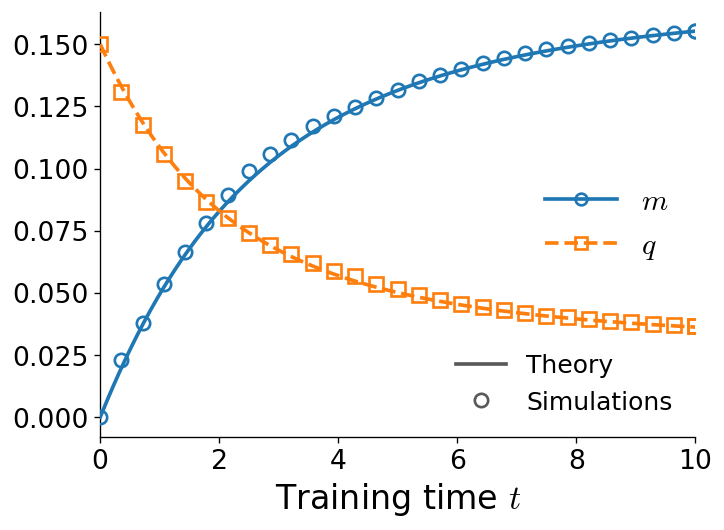

In [3]:
fig, ax = P.concentration_figure(ode, sgd['traj'], p.t_F)
fig.savefig('figures/fig_concentration.pdf')